In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

## Swim Speed

Text(0.5, 0, 'delta z')

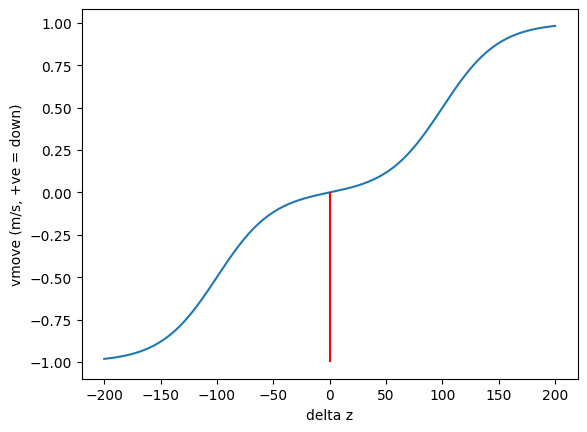

In [5]:
swim_max = 0.025 # m s-1
VM_layer_width = 50 # m   # Width of the slow-migration layer (e.g. at surface)
VM_inflection_width = 50 # m

delta_z = np.arange(-200, 200, 0.01)

def vmove_model(delta_z):
    return swim_max * 0.5*( np.tanh((delta_z - (VM_layer_width+VM_inflection_width))/VM_inflection_width) + np.tanh((delta_z + (VM_layer_width+VM_inflection_width))/VM_inflection_width))


vmove = np.zeros(len(delta_z))
vmove = vmove_model(delta_z)

plt.plot(delta_z, vmove/swim_max)
plt.vlines(0,-1,0,'r')
plt.ylabel("vmove (m/s, +ve = down)")
plt.xlabel("delta z")

## Bresp Dormant Lim

Text(0.5, 0, 'z')

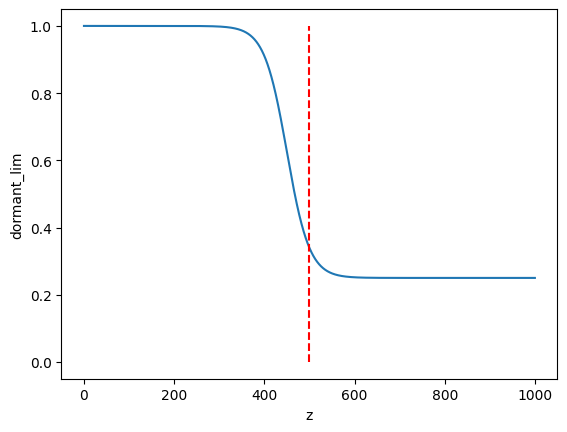

In [3]:
BL = 50
pMLD = 500
BL_depth_PLUS_250 = BL + pMLD

dorm_frac = 0.25

z = np.arange(0, 1000, 0.1)

def T_lim(z):
    #return 1 - (1-dorm_frac) * 0.5 * (1+np.tanh((z - BL_depth_PLUS_250 + (VM_layer_width+2.0*VM_inflection_width))/VM_inflection_width))
    return 1 - (1-dorm_frac) * 0.5 * (1  +  np.tanh((z - (pMLD - VM_layer_width))/VM_inflection_width))

dormant_lim = np.zeros(len(z))
dormant_lim = T_lim(z)

plt.plot(z, dormant_lim)
#plt.vlines(BL_depth_PLUS_250, 0, 1, colors='k', linestyles='dashed')
#plt.vlines(BL, 0, 1, colors='k', linestyles='dashed')
#plt.vlines(BL_depth_PLUS_250-VM_layer_width, 0, 1, colors='r', linestyles='dashed')
plt.vlines(pMLD, 0, 1, colors='r', linestyles='dashed')
plt.ylabel("dormant_lim")
plt.xlabel("z")

Text(0.5, 0, 'z')

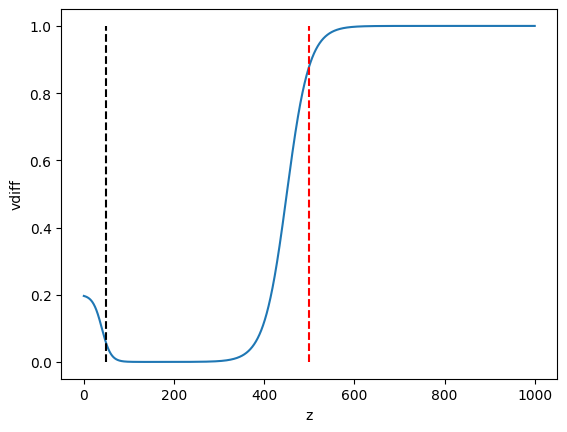

In [4]:

vdiff = (1.0 - dormant_lim) / (1.0-0.25) + 0.1*(1.0 - np.tanh((z - (BL-10))/20))

plt.plot(z, vdiff)
#plt.vlines(BL_depth_PLUS_250, 0, 1, colors='k', linestyles='dashed')
plt.vlines(BL, 0, 1, colors='k', linestyles='dashed')
#plt.vlines(BL_depth_PLUS_250-VM_layer_width, 0, 1, colors='r', linestyles='dashed')
plt.vlines(pMLD, 0, 1, colors='r', linestyles='dashed')
plt.ylabel("vdiff")
plt.xlabel("z")

## HP Light Limitation
### Want limitation to be still ~1 in the top surface !

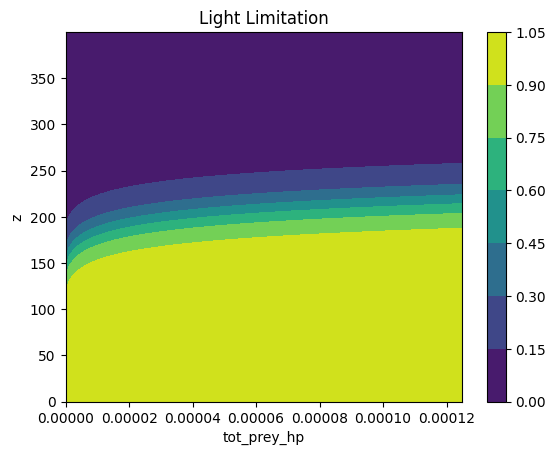

Text(0.5, 0, 'z')

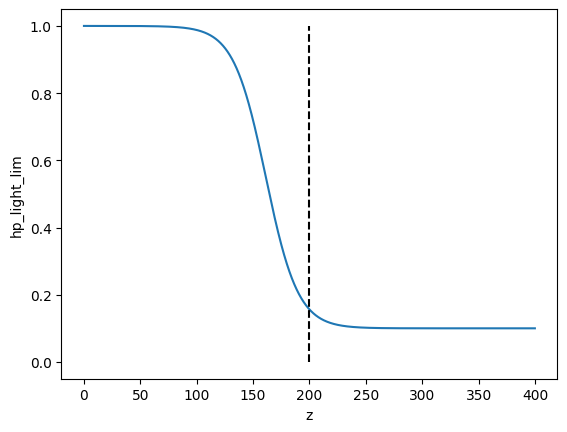

In [7]:
# Richards 1996 Model for Light Intensity / Variation
I_surf = 400.0 # W m-2
a = 0.07 # m-1


ki_hp = 1.25e-6
visual_hp = 0.9
k_Irr_hp = 0.1

def zeta(z):
    return np.exp(-a*z)

def I_irr(z):
    return I_surf * zeta(z)

z = np.arange(0, 400, 0.1)
tot_prey_hp = np.linspace(0, 100*ki_hp, 100)

def light_lim(z,tot_prey_hp):
    return (1.0 - visual_hp)  +  visual_hp * I_irr(z) / \
                     (ki_hp/(ki_hp+tot_prey_hp)*k_Irr_hp  +  I_irr(z))


# Create a meshgrid of z and tot_prey_hp values
Z, TOT_PREY_HP = np.meshgrid(z, tot_prey_hp)

# Calculate light_lim for each combination of z and tot_prey_hp
LIGHT_LIM = light_lim(Z, TOT_PREY_HP)

# Create a contour plot
plt.contourf(TOT_PREY_HP, Z, LIGHT_LIM)
plt.colorbar()
plt.xlabel('tot_prey_hp')
plt.ylabel('z')
plt.title('Light Limitation')
plt.show()



plt.plot(z, light_lim(z, 1.0*ki_hp))
plt.vlines(200, 0, 1, colors='k', linestyles='dashed')
plt.ylabel("hp_light_lim")
plt.xlabel("z")